# 05 · Pronóstico: ¿cuánta gente va a pasar por el subte en los próximos meses?

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ValentinoDiaz0509/CienciaDeDatos/blob/main/notebooks/05_pronostico_subte.ipynb)

**TPO Ciencia de Datos · ¿Dónde faltan cajeros Link en CABA?**

El notebook 02 predice **dónde**: cuántos cajeros le corresponden a cada zona. Este predice **cuándo**: cuánta gente va a
entrar al subte cada día de los próximos meses. Son las dos caras del análisis predictivo:

| | Notebook 02 | Notebook 05 |
|---|---|---|
| Pregunta | ¿Cuántos cajeros le corresponden a cada zona? | ¿Cuánta gente va a pasar por las estaciones cada día? |
| Datos | una foto de la ciudad (censo, usos del suelo, OpenStreetMap) | la serie diaria de los molinetes (SBASE), de enero de 2025 a agosto de 2026 |
| Modelos | regresión de conteos: árboles, Random Forest, XGBoost | regresión sobre el calendario: Random Forest y XGBoost |
| Validación | espacial: comunas que el modelo no vio | hacia adelante: meses que el modelo no vio |

**Para qué le sirve a Red Link**

- **Gerencia Técnica:** planificar la carga de efectivo y el mantenimiento de los cajeros cerca de las estaciones: cuándo
  va a haber más gente y en qué días y meses conviene hacer los trabajos.
- **Gerencia Comercial:** cuánta gente va a pasar por las estaciones que hoy no tienen un Link a distancia caminable.

**Cómo correrlo.** La serie diaria ya está en `data/base/` (la armó el notebook 00c en Colab, a partir de los archivos de
molinetes de BA Data). Si faltara, en Colab este notebook la baja (tarda entre 20 y 40 minutos).

In [1]:
# Preparar el entorno: en Colab clona el repo y, si falta, baja la serie diaria
import json, subprocess, sys, shutil, zipfile
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAIZ = Path("/content/CienciaDeDatos")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/ValentinoDiaz0509/CienciaDeDatos.git", str(RAIZ)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "holidays", "xgboost", "h3"], check=True)
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src import estilo as e, pronostico as pr
from src.features import DIR_BASE

import matplotlib.dates as mdates

e.mpl_estilo()
FIG = RAIZ / "docs/figuras"; FIG.mkdir(parents=True, exist_ok=True)
PROC = RAIZ / "data/processed"
MES_CORTO = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]


def eje_meses(ax, cada=1):   # marcas mensuales en castellano: "abr 26"
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=cada))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{MES_CORTO[mdates.num2date(x).month - 1]} {mdates.num2date(x):%y}"))

if not pr.hay_serie(DIR_BASE):
    zip_serie = RAIZ / "data/serie_subte.zip"
    if not zip_serie.exists() and EN_COLAB:
        from src import descarga
        zip_serie = descarga.descargar_serie_subte()
    if not zip_serie.exists():
        raise FileNotFoundError("Falta la serie diaria del subte: correr notebooks/00c_serie_diaria_subte.ipynb en Colab "
                                "y dejar serie_subte.zip en data/ (o sus dos archivos en data/base/).")
    with zipfile.ZipFile(zip_serie) as z:
        for nombre in (pr.ARCHIVO_DIARIO, pr.ARCHIVO_HORA):
            if nombre in z.namelist():
                z.extract(nombre, DIR_BASE)
print("Serie diaria:", DIR_BASE / pr.ARCHIVO_DIARIO)

Serie diaria: /home/claude/cienciadedatos/data/base/subte-diario-estacion.parquet


## 1. La serie

Sumamos las entradas de todas las estaciones para tener **pasajeros por día en toda la red**. Antes de modelar marcamos los
**días anómalos**, que no se pueden predecir con el calendario y por eso no se usan para entrenar ni para medir el error:

- los que tienen **menos de la mitad** de los pasajeros de un día igual en las semanas de alrededor (paros, cortes de
  servicio, archivos incompletos);
- los que tienen **más de 1,25 veces** (registros repetidos);
- los que tienen la **fecha mal cargada** en el archivo de origen (lo explicamos abajo).

Los feriados no cuentan como anomalía: son justamente lo que el modelo tiene que aprender.

In [2]:
diario, hora = pr.cargar(DIR_BASE)
s = pr.serie_red(diario)
anomalia = pr.marcar_anomalias(s)
fin = s.dropna().index.max()
print(f"Desde {s.dropna().index.min():%d/%m/%Y} hasta {fin:%d/%m/%Y}: {e.num_es(s.notna().sum())} días con datos, "
      f"{e.num_es(s.isna().sum())} sin datos y {e.num_es((anomalia & s.notna()).sum())} anómalos")
reciente = s[(s.index > fin - pd.DateOffset(years=1)) & (s.index.dayofweek < 5)]
print(f"Estaciones: {diario.groupby(['linea', 'estacion']).ngroups} · "
      f"día hábil típico del último año: {e.num_es(reciente.median())} entradas")
pd.DataFrame({"pasajeros": s[anomalia & s.notna()]}).assign(dia=lambda d: d.index.day_name()).tail(10)

Desde 01/01/2025 hasta 31/08/2026: 578 días con datos, 30 sin datos y 28 anómalos
Estaciones: 106 · día hábil típico del último año: 745.326 entradas


,pasajeros,dia
2025-08-11,534221.0,Monday
2025-08-12,581986.0,Tuesday
2025-09-08,880059.0,Monday
2025-10-08,856022.0,Wednesday
2025-11-08,536957.0,Saturday
2025-12-08,467258.0,Monday
2025-12-21,210588.0,Sunday
2025-12-22,721163.0,Monday
2026-02-19,13.0,Thursday
2026-04-18,455835.0,Saturday


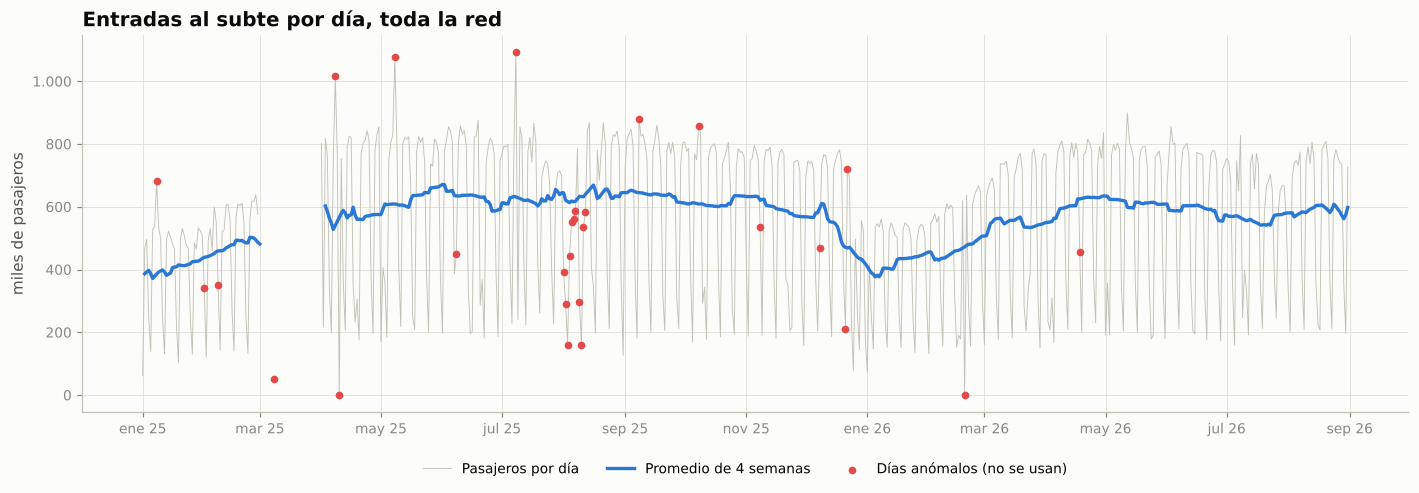

In [3]:
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.plot(s.index, s / 1e3, color=e.EJE, linewidth=0.6, label="Pasajeros por día")
semanal = s.where(~anomalia).rolling(28, center=True, min_periods=14).mean()
ax.plot(semanal.index, semanal / 1e3, color=e.LINK, linewidth=2.2, label="Promedio de 4 semanas")
an = s[anomalia & s.notna()]
ax.scatter(an.index, an / 1e3, s=16, color=e.DIVERGENTE[-2], zorder=3, label="Días anómalos (no se usan)")
ax.set(title="Entradas al subte por día, toda la red", ylabel="miles de pasajeros")
eje_meses(ax, 2); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
e.ejes_es(ax, y=0); fig.tight_layout(); fig.savefig(FIG / "pron_serie.png"); plt.show()

### Un error en los datos abiertos: fechas con el día y el mes invertidos

Al revisar los días anómalos apareció un patrón: en 2025, **el día 8 de casi todos los meses tiene un tercio más de
pasajeros** de lo normal, en todas las líneas y en todas las horas por igual, y **del 1 al 12 de agosto falta más o menos
lo mismo**. La explicación: una parte de los registros de esos días de agosto trae la fecha como mes/día (`08/04/2025`
es el 4 de agosto) y, leída como día/mes, que es el formato del resto del archivo, cae en el 8 de abril. El 8 de agosto no
cambia porque se lee igual de las dos formas, y del 13 en adelante no hay confusión posible (no existe el mes 13).

La prueba más clara: **marzo de 2025 no está en el archivo, pero el 8 de marzo tiene entradas**, y sumadas al 3 de agosto
dan un domingo normal. En 2026 no pasa: sirve de control.

In [4]:
tipico = pr.tipico_dia(s, anomalia)        # mediana de los días normales iguales en las 8 semanas de alrededor
cal_s = pr.calendario(s.index)
feriado_s = cal_s[["feriado", "puente", "no_laborable"]].sum(axis=1) > 0
pct = 100 * s / tipico


def mediana_pct(fechas):
    fechas = [f for f in fechas if f in pct.index and pd.notna(pct[f]) and not feriado_s[f]]
    return pct[fechas].median()


pd.DataFrame({anio: {"el día 8 de cada mes (menos agosto)": mediana_pct([pd.Timestamp(anio, m, 8) for m in range(1, 13) if m != 8]),
                     "del 1 al 12 de agosto (menos el 8)": mediana_pct([pd.Timestamp(anio, 8, d) for d in range(1, 13) if d != 8])}
              for anio in (2025, 2026)}).round(0).rename_axis("% de un día típico")

,2025,2026
% de un día típico,,
el día 8 de cada mes (menos agosto),133.0,104.0
del 1 al 12 de agosto (menos el 8),72.0,100.0


In [5]:
print(f"8 de marzo de 2025 (marzo no está en el archivo): {e.num_es(s['2025-03-08'])} entradas. "
      f"3 de agosto: {e.num_es(s['2025-08-03'])}. Suma: {e.num_es(s['2025-03-08'] + s['2025-08-03'])}, "
      f"contra {e.num_es(tipico['2025-08-03'])} de un domingo típico.")
cruzadas = pr.fechas_cruzadas(s)   # busca el patrón en cualquier mes y año de la serie
por_mes_c = pd.Series(cruzadas.to_period("M")).value_counts()   # el mes afectado aporta 11 días; los demás, uno
print("Mes con fechas cruzadas:", ", ".join(pr.nombre_mes(m.to_timestamp()) for m in sorted(por_mes_c[por_mes_c >= 6].index)) or "ninguno")
print(f"Marcamos como anómalos los {len(cruzadas)} días afectados: no entran ni al entrenamiento ni a la medición.")

8 de marzo de 2025 (marzo no está en el archivo): 51.642 entradas. 3 de agosto: 160.584. Suma: 212.226, contra 223.783 de un domingo típico.
Mes con fechas cruzadas: agosto de 2025
Marcamos como anómalos los 22 días afectados: no entran ni al entrenamiento ni a la medición.


**Qué hicimos.** No se pueden separar los registros mezclados (la suma por día ya los junta), así que esos 22 días quedan afuera del modelo. No los marcamos a mano: `pr.fechas_cruzadas` busca el patrón en
cualquier mes y año (días 1 a 12 de un mes con menos gente y el mismo número de día en los otros meses con más), así que si
se suman años a la serie también los encuentra. Es un hallazgo para reportar a BA Data: quien use el archivo de 2025 sin revisarlo va a ver picos
de demanda el 8 de cada mes que no existen.

### Los patrones que tiene que aprender el modelo

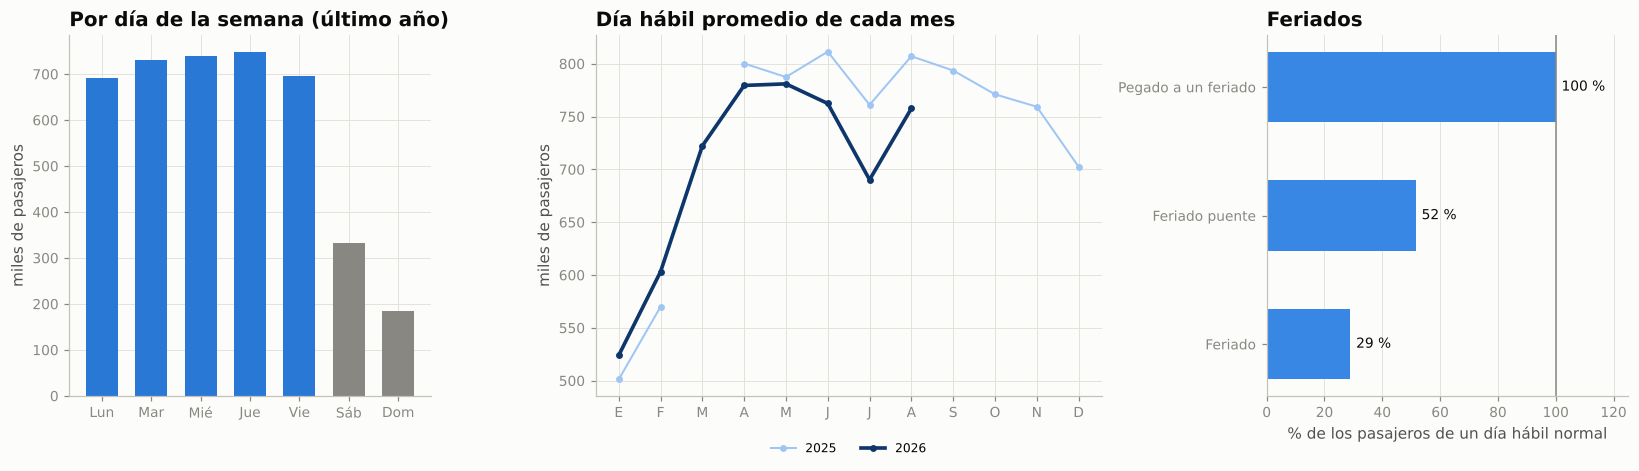

Un sábado tiene el 46 % de un día hábil y un domingo el 26 %. Enero tiene el 65 % del mes de más pasajeros.


In [6]:
cal = pr.calendario(s.index)
normal = s.where(~anomalia)
habil = (cal["fin_de_semana"] == 0) & (cal[["feriado", "puente", "no_laborable"]].sum(axis=1) == 0)
ultimo_anio = s.index > fin - pd.DateOffset(years=1)
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1.4, 1]})
sin_feriado = ultimo_anio & (cal[["feriado", "puente"]].sum(axis=1) == 0).to_numpy()
por_dia = normal[sin_feriado].groupby(s.index[sin_feriado].dayofweek).mean()
ax[0].bar(dias, por_dia.values / 1e3, color=[e.LINK] * 5 + [e.TINTA_SUAVE] * 2, width=0.65)
ax[0].set(title="Por día de la semana (último año)", ylabel="miles de pasajeros")

mensual = normal[habil.to_numpy()].groupby([s.index[habil.to_numpy()].year, s.index[habil.to_numpy()].month]).mean().unstack(0)
anios = list(mensual.columns)
tonos = np.linspace(1, 6, len(anios)).round().astype(int)   # de claro (años viejos) a oscuro (el último)
for k, anio in enumerate(anios):
    ultimo = anio == anios[-1]
    ax[1].plot(mensual.index, mensual[anio] / 1e3, marker="o", markersize=3.5, linewidth=2.4 if ultimo else 1.3,
               color=e.SECUENCIAL[tonos[k]], label=str(anio))
ax[1].set_xticks(range(1, 13), ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax[1].set(title="Día hábil promedio de cada mes", ylabel="miles de pasajeros")
ax[1].legend(ncol=len(anios), loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8, frameon=False)

tipico = normal.groupby([s.index.year, s.index.month, s.index.dayofweek]).transform("median")
efecto = (normal / tipico)[(cal["dia_semana"] < 5).to_numpy()]
grupos = {"Feriado": cal["feriado"] == 1, "Feriado puente": cal["puente"] == 1,
          "Pegado a un feriado": cal["pegado_feriado"] == 1}
valores = {k: float(efecto[v[(cal["dia_semana"] < 5)].to_numpy()].median() * 100) for k, v in grupos.items()}
ax[2].barh(list(valores), list(valores.values()), color=e.DIVERGENTE[1], height=0.55)
for i, v in enumerate(valores.values()):
    ax[2].text(v + 2, i, f"{e.num_es(v)} %", va="center", fontsize=9, color=e.TINTA)
ax[2].axvline(100, color=e.TINTA_SUAVE, linewidth=1)
ax[2].set(title="Feriados", xlim=(0, 125), xlabel="% de los pasajeros de un día hábil normal")
for a in ax[:2]:
    e.ejes_es(a, y=0)
ax[2].grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "pron_patrones.png"); plt.show()
print(f"Un sábado tiene el {e.num_es(100 * por_dia[5] / por_dia[:5].mean())} % de un día hábil y un domingo el "
      f"{e.num_es(100 * por_dia[6] / por_dia[:5].mean())} %. Enero tiene el "
      f"{e.num_es(100 * mensual.loc[1].mean() / mensual.mean(axis=1).max())} % del mes de más pasajeros.")

**Lectura.** La demanda depende sobre todo del **calendario**: los días hábiles tienen mucha más gente que los fines de
semana, los feriados se parecen a un domingo, el verano (enero y febrero) cae fuerte y se recupera en marzo. Por eso el
modelo usa como variables solo el calendario: se conocen con meses de anticipación, así que se puede pronosticar
cualquier fecha futura.

## 2. Modelo y validación

**Variables (todas del calendario):**

In [7]:
pd.DataFrame({"variable": pr.VARIABLES, "qué mide": [pr.NOMBRES[v] for v in pr.VARIABLES]})

,variable,qué mide
0,dia_semana,Día de la semana
1,fin_de_semana,Fin de semana
2,mes,Mes
3,dia_mes,Día del mes
4,dia_anio_sin,Época del año (seno)
5,dia_anio_cos,Época del año (coseno)
6,semana_mes,Semana del mes
7,feriado,Feriado
8,puente,Feriado puente
9,no_laborable,Día no laborable


- **Objetivo:** el logaritmo de los pasajeros del día (así el error es relativo: equivocarse en 50 mil pasajeros pesa
  más un domingo que un día hábil).
- **Modelos (clases 6 y 8):** **Random Forest** (500 árboles) y **XGBoost** (boosting de 800 árboles poco profundos).
- **Referencia ingenua:** "el mismo día de la semana del año anterior". Un modelo que no le gane a esto no sirve.
- **Validación hacia adelante:** se entrena solo con el pasado y se mide en los meses siguientes, que el modelo no vio.
  Lo hacemos dos veces, con los dos períodos de cuatro meses más recientes y siempre con al menos un año de historia para
  entrenar (origen móvil). Nunca se usan fechas futuras para entrenar: sería hacer trampa, porque en la realidad el futuro
  no se conoce.
- **Comparación justa:** los tres se miden en los mismos días (los normales en los que la referencia tiene valor; por eso
  marzo, que falta en 2025, no entra en el primer período).
- **Métricas:** MAPE (error porcentual medio por día), MAE (pasajeros por día) y error del total del período.

In [8]:
cortes = pr.cortes_validacion(s)
for nombre, fin_tr, fin_te in cortes:
    print(f"Prueba {nombre}: entrena hasta el {pd.Timestamp(fin_tr):%d/%m/%Y}, mide hasta el {pd.Timestamp(fin_te):%d/%m/%Y}")
met, preds = pr.validar(s, anomalia, cortes)
promedio = met.groupby("modelo")["MAPE (%)"].mean().sort_values()
elegido = next(m for m in promedio.index if m != "Mismo día del año anterior")
met.set_index(["período de prueba", "modelo"]).round(2)

Prueba enero a abril de 2026: entrena hasta el 31/12/2025, mide hasta el 30/04/2026
Prueba mayo a agosto de 2026: entrena hasta el 30/04/2026, mide hasta el 31/08/2026


MAPE (%)  \
período de prueba     modelo                                 
enero a abril de 2026 Mismo día del año anterior     26.67   
                      Random Forest                   9.17   
                      XGBoost                         8.13   
mayo a agosto de 2026 Mismo día del año anterior     17.70   
                      Random Forest                   6.76   
                      XGBoost                         8.28   

                                                  MAE (pasajeros/día)  \
período de prueba     modelo                                            
enero a abril de 2026 Mismo día del año anterior             79717.41   
                      Random Forest                          36649.15   
                      XGBoost                                36945.47   
mayo a agosto de 2026 Mismo día del año anterior             72491.43   
                      Random Forest                          33275.72   
                      XGBoost                                42194.33   

                                                  error del total (%)  \
período de prueba     modelo                                            
enero a abril de 2026 Mismo día del año anterior                -1.91   
                      Random Forest                             -5.27   
                      XGBoost                                   -4.27   
mayo a agosto de 2026 Mismo día del año anterior                 6.63   
                      Random Forest                              4.43   
                      XGBoost                                    6.32   

                                                  días evaluados  
período de prueba     modelo                                      
enero a abril de 2026 Mismo día del año anterior              88  
                      Random Forest                           88  
                      XGBoost                                 88  
mayo a agosto de 2026 Mismo día del año anterior             123  
                      Random Forest                          123  
                      XGBoost                                123

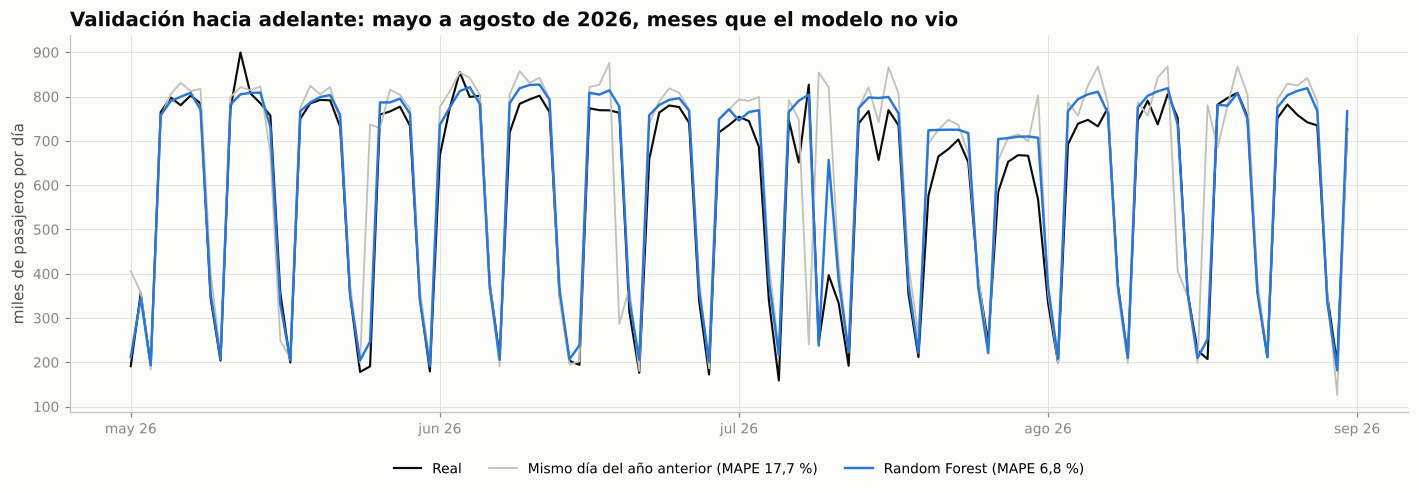

Modelo elegido: Random Forest. Erra en promedio un 8,0 % por día, contra 22,2 % de la referencia ingenua: su error es el 36 % del de la referencia.


In [9]:
ultimo = cortes[-1][0]
p = preds[preds["periodo"] == ultimo].pivot_table(index="fecha", columns="modelo", values=["real", "prediccion"])
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.plot(p.index, p[("real", elegido)] / 1e3, color=e.TINTA, linewidth=1.4, label="Real")
ax.plot(p.index, p[("prediccion", "Mismo día del año anterior")] / 1e3, color=e.EJE, linewidth=1.2,
        label=f"Mismo día del año anterior (MAPE {e.num_es(met.set_index(['período de prueba', 'modelo']).loc[(ultimo, 'Mismo día del año anterior'), 'MAPE (%)'], 1)} %)")
ax.plot(p.index, p[("prediccion", elegido)] / 1e3, color=e.LINK, linewidth=1.6,
        label=f"{elegido} (MAPE {e.num_es(met.set_index(['período de prueba', 'modelo']).loc[(ultimo, elegido), 'MAPE (%)'], 1)} %)")
ax.set(title=f"Validación hacia adelante: {ultimo}, meses que el modelo no vio", ylabel="miles de pasajeros por día")
eje_meses(ax); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
e.ejes_es(ax, y=0); fig.tight_layout(); fig.savefig(FIG / "pron_validacion.png"); plt.show()
m_el = met[met["modelo"] == elegido]["MAPE (%)"].mean()
m_in = met[met["modelo"] == "Mismo día del año anterior"]["MAPE (%)"].mean()
print(f"Modelo elegido: {elegido}. Erra en promedio un {e.num_es(m_el, 1)} % por día, contra {e.num_es(m_in, 1)} % de la "
      f"referencia ingenua: su error es el {e.num_es(100 * m_el / m_in)} % del de la referencia.")

**Lectura.** Si el modelo erra poco **día por día** y poco en el **total del período**, sirve para planificar: el
error de un día puntual se compensa a lo largo del mes. Los días que más erra suelen ser los que tienen algo que el
calendario no sabe (lluvia fuerte, un evento, un paro parcial). Random Forest y XGBoost quedan cerca; elegimos el de menor
error promedio en los dos períodos.

## 3. Qué aprendió el modelo

Importancia de cada variable en el modelo elegido: cuánto baja el error, en promedio, cada vez que un árbol corta por esa
variable (la reducción de varianza, que es la versión para regresión de la importancia de Gini de la clase 8). *Día de la
semana* y *fin de semana* miden casi lo mismo, así que se reparten la importancia.

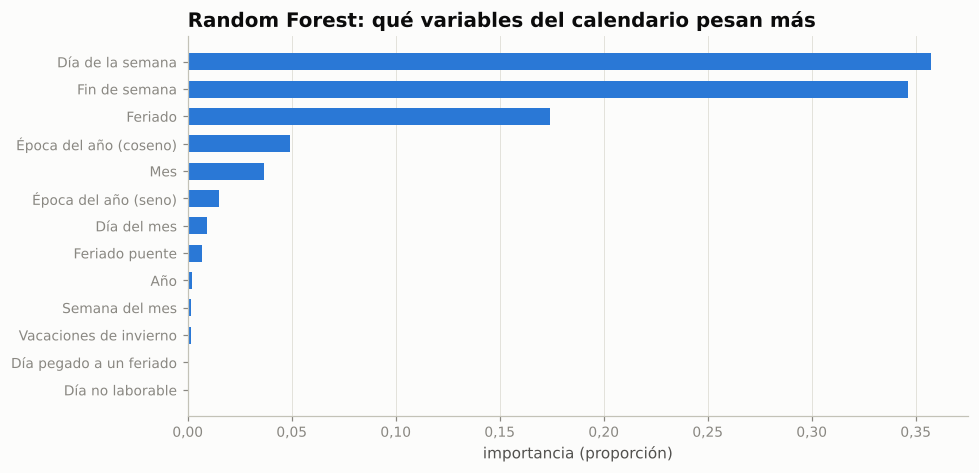

In [10]:
imp = pr.importancia(s, anomalia, elegido)
fig, ax = plt.subplots(figsize=(9, 4.4))
d = imp.sort_values()
ax.barh([pr.NOMBRES[v] for v in d.index], d.values, color=e.LINK, height=0.62)
ax.set(title=f"{elegido}: qué variables del calendario pesan más", xlabel="importancia (proporción)")
ax.grid(axis="y", visible=False); e.ejes_es(ax, x=2); fig.tight_layout(); fig.savefig(FIG / "pron_importancia.png"); plt.show()

## 4. Pronóstico

Entrenamos con **toda** la serie y pronosticamos día por día los seis meses siguientes al último dato. La banda es un
**intervalo del 80 %**: lo estimamos con dos modelos XGBoost de cuantiles (10 y 90), que aprenden el rango en el que
suelen caer los días de cada tipo.

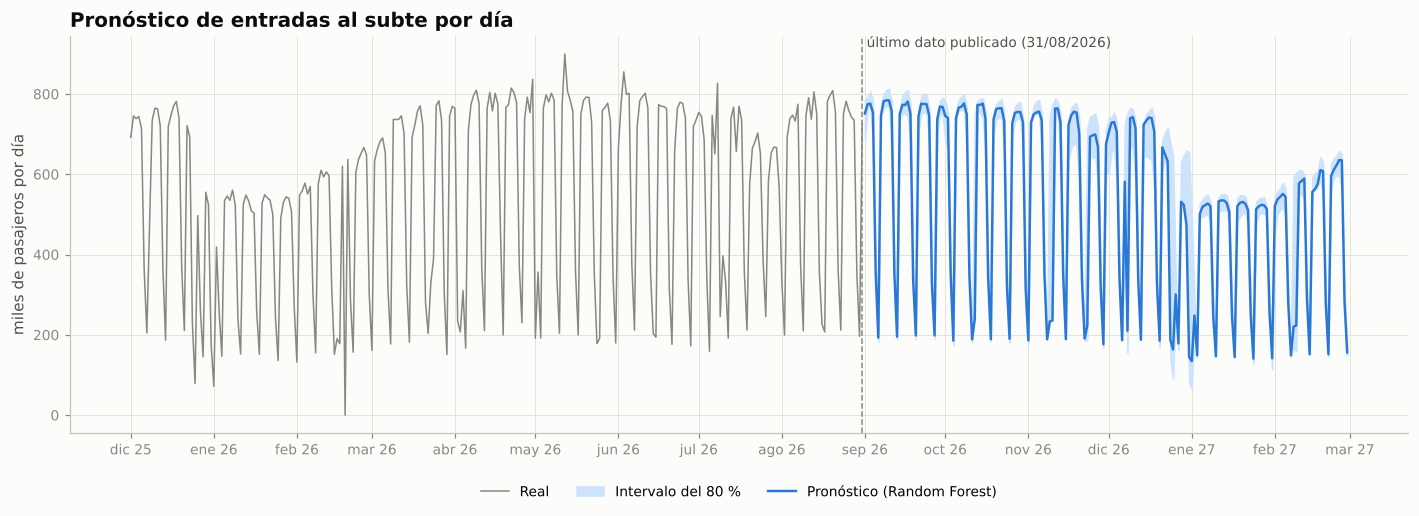

,día hábil promedio,mínimo probable,máximo probable,"mismo mes, año anterior",variación (%)
mes,,,,,
septiembre de 2026,764862.0,733743.0,787142.0,793557.0,-4.0
octubre de 2026,753633.0,718109.0,771230.0,771039.0,-2.0
noviembre de 2026,727429.0,675652.0,755779.0,759279.0,-4.0
diciembre de 2026,677128.0,608722.0,722894.0,702493.0,-4.0
enero de 2027,521899.0,495437.0,538552.0,523962.0,-0.0
febrero de 2027,581133.0,546182.0,607081.0,603076.0,-4.0


In [11]:
pron = pr.pronosticar(s, anomalia, pr.horizonte(fin), elegido)
desde = fin - pd.DateOffset(months=9)
fig, ax = plt.subplots(figsize=(13, 4.8))
reciente = s[s.index > desde]
ax.plot(reciente.index, reciente / 1e3, color=e.TINTA_SUAVE, linewidth=1, label="Real")
ax.fill_between(pron["fecha"], pron["p10"] / 1e3, pron["p90"] / 1e3, color=e.SECUENCIAL[0], label="Intervalo del 80 %")
ax.plot(pron["fecha"], pron["pronostico"] / 1e3, color=e.LINK, linewidth=1.6, label=f"Pronóstico ({elegido})")
ax.axvline(fin, color=e.TINTA_SUAVE, linewidth=1, linestyle="--")
ax.text(fin, ax.get_ylim()[1], f" último dato publicado ({fin:%d/%m/%Y})", va="top", fontsize=9, color=e.TINTA_2)
ax.set(title="Pronóstico de entradas al subte por día", ylabel="miles de pasajeros por día")
eje_meses(ax); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
e.ejes_es(ax, y=0); fig.tight_layout(); fig.savefig(FIG / "pron_pronostico.png"); plt.show()
mensual_p = pr.por_mes(s, anomalia, pron)
(mensual_p.rename(columns={"pronostico": "día hábil promedio", "p10": "mínimo probable", "p90": "máximo probable",
                           "anio_anterior": "mismo mes, año anterior", "variacion_%": "variación (%)"})
 .rename(index=lambda p_: pr.nombre_mes(p_.to_timestamp())).round(0))

In [12]:
habiles = pron[pron["tipo_dia"] == "hábil"]
pico = habiles.loc[habiles["pronostico"].idxmax()]
valle = habiles.loc[habiles["pronostico"].idxmin()]
largos = pron[pron["tipo_dia"] == "feriado"]
print(f"Día hábil con más gente: {pico['fecha']:%d/%m/%Y} ({e.num_es(pico['pronostico'])} entradas). "
      f"Con menos: {valle['fecha']:%d/%m/%Y} ({e.num_es(valle['pronostico'])}).")
domingos = pron[pron["fecha"].dt.dayofweek == 6]["pronostico"].mean()
if len(largos):
    print("Feriados en el período:", ", ".join(f"{f:%d/%m}" for f in largos["fecha"]),
          f"· en promedio {e.num_es(largos['pronostico'].mean())} entradas (un domingo: {e.num_es(domingos)}).")

Día hábil con más gente: 10/09/2026 (784.357 entradas). Con menos: 30/12/2026 (474.819).
Feriados en el período: 12/10, 09/11, 10/11, 23/11, 07/12, 08/12, 24/12, 25/12, 31/12, 01/01, 08/02, 09/02 · en promedio 232.967 entradas (un domingo: 174.423).


## 5. Por estación y por hora

Para bajar el pronóstico a cada estación usamos su **parte** de las entradas de la red en los últimos tres meses (las
estaciones cambian de peso muy despacio). Así sale cuánta gente va a entrar por día hábil a cada una, y en particular a
las que hoy **no tienen un Link** a distancia caminable.

In [13]:
res = pr.resultados(DIR_BASE, PROC)   # guarda las tablas para la app y la presentación
est = pd.read_csv(PROC / "pronostico_estaciones.csv")
print(f"Pronóstico para {res['primer_mes_nombre']}: {e.num_es(res['pax_habil_primer_mes'])} entradas por día hábil en "
      f"toda la red ({'+' if res['variacion_primer_mes_pct'] >= 0 else ''}{e.num_es(res['variacion_primer_mes_pct'], 1)} % "
      "contra el mismo mes del año anterior).")
print(f"Las {res['estaciones_sin_link']} estaciones sin un Link cerca van a recibir unas "
      f"{e.num_es(res['pax_habil_estaciones_sin_link'])} entradas por día hábil.")
(est[~est["link_cerca"].astype(bool)][["linea", "estacion", "perfil", "pax_habil_reciente", "pax_habil_pronostico"]]
 .rename(columns={"pax_habil_reciente": "por día hábil (últimos 3 meses)", "pax_habil_pronostico": f"por día hábil ({res['primer_mes_nombre']})"})
 .round(0))

Pronóstico para septiembre de 2026: 764.862 entradas por día hábil en toda la red (-3,6 % contra el mismo mes del año anterior).
Las 10 estaciones sin un Link cerca van a recibir unas 44.593 entradas por día hábil.


,linea,estacion,perfil,por día hábil (últimos 3 meses),por día hábil (septiembre de 2026)
36,E,Plaza de los Virreyes - Eva Perón,Origen: la gente sale de su casa (pico a la ma...,8225.0,8542.0
50,H,Venezuela,Origen: la gente sale de su casa (pico a la ma...,6328.0,6573.0
56,H,Facultad de Derecho - Julieta Lanteri,Destino: la gente vuelve del trabajo (pico a l...,5424.0,5633.0
63,E,Avenida La Plata,Origen: la gente sale de su casa (pico a la ma...,4903.0,5093.0
66,H,Inclán-Mezquita Al Ahmad,Origen: la gente sale de su casa (pico a la ma...,4557.0,4734.0
69,E,Emilio Mitre,Origen: la gente sale de su casa (pico a la ma...,4309.0,4475.0
83,E,San José,Origen: la gente sale de su casa (pico a la ma...,2492.0,2588.0
84,E,Pichincha,Origen: la gente sale de su casa (pico a la ma...,2405.0,2498.0
86,E,General Urquiza,Origen: la gente sale de su casa (pico a la ma...,2216.0,2302.0
87,E,Medalla Milagrosa,Origen: la gente sale de su casa (pico a la ma...,2074.0,2155.0


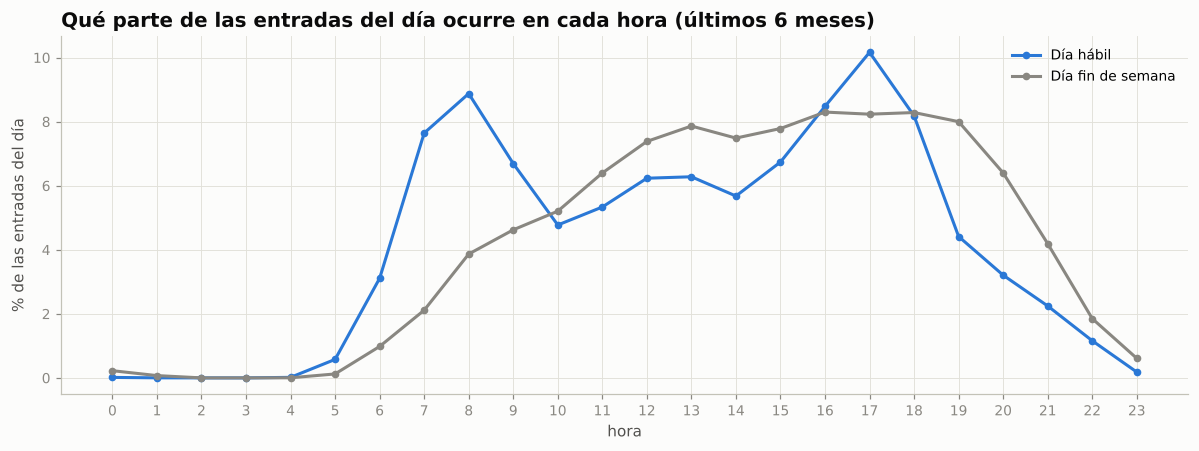

En un día hábil, entre las 7 y las 10 entra el 23 % de la gente y entre las 17 y las 20, el 23 %. Con el pronóstico de septiembre de 2026, son unas 177.533 personas en el pico de la mañana.


In [14]:
if hora is not None:
    perfil = pr.perfil_horario(hora)
    fig, ax = plt.subplots(figsize=(11, 4.2))
    for tipo, color in (("hábil", e.LINK), ("fin de semana", e.TINTA_SUAVE)):
        d = perfil[perfil["tipo_dia"] == tipo]
        ax.plot(d["hora"], 100 * d["parte"], marker="o", markersize=4, linewidth=2, color=color, label=f"Día {tipo}")
    ax.set(title="Qué parte de las entradas del día ocurre en cada hora (últimos 6 meses)", xlabel="hora",
           ylabel="% de las entradas del día")
    ax.set_xticks(range(0, 24))
    ax.legend(); e.ejes_es(ax, y=0); fig.tight_layout(); fig.savefig(FIG / "pron_horario.png"); plt.show()
    h = perfil[perfil["tipo_dia"] == "hábil"].set_index("hora")["parte"]
    print(f"En un día hábil, entre las 7 y las 10 entra el {e.num_es(100 * h.loc[7:9].sum())} % de la gente y entre las 17 y "
          f"las 20, el {e.num_es(100 * h.loc[17:19].sum())} %. Con el pronóstico de {res['primer_mes_nombre']}, son unas "
          f"{e.num_es(res['pax_habil_primer_mes'] * h.loc[7:9].sum())} personas en el pico de la mañana.")

## 6. Conclusión

- **Técnica:** con variables de calendario, **Random Forest** erra en promedio un **8,0 %** por día en meses que no vio, contra 22,2 % de la referencia ingenua (el mismo día del año anterior): su error es el 36 % del de la referencia. En el total del último período de prueba (mayo a agosto de 2026) sobreestima un 4,4 %.
- **Negocio:** la demanda de paso se puede **anticipar**. Para septiembre de 2026 el modelo espera unas **764.862 entradas por día hábil** (-3,6 % contra un año antes) y para enero de 2027, el mes más bajo, unas 521.899. Las 10 estaciones sin un Link cerca van a recibir unas 44.593 entradas por día hábil. La Gerencia Técnica puede planificar la
  carga de efectivo antes de los días de más gente y concentrar el mantenimiento y las instalaciones en los días y meses de
  menos flujo (fines de semana, feriados y el verano). La Comercial sabe cuánta gente va a pasar por las estaciones sin un
  Link cerca.
- **Datos:** la serie va de enero de 2025 a agosto de 2026 (el catálogo de BA Data no respondió para años anteriores). Al archivo
  de 2025 le falta marzo y tiene 22 días con la fecha mal cargada, que encontramos y dejamos afuera.
  Con más años, el modelo aprendería mejor la estacionalidad; el notebook 00c los baja.
- **Limitación:** los molinetes cuentan gente que entra al subte, no extracciones. Es un indicador del flujo de personas
  cerca de las estaciones, no de la demanda de efectivo, que es un dato privado de las redes.

In [15]:
if EN_COLAB:   # para pasarle la serie al grupo
    zip_serie = RAIZ / "data/serie_subte.zip"
    if zip_serie.exists():
        from google.colab import files
        files.download(str(zip_serie))